In [3]:
import cv2
from matplotlib import pyplot as plt
import numpy as np

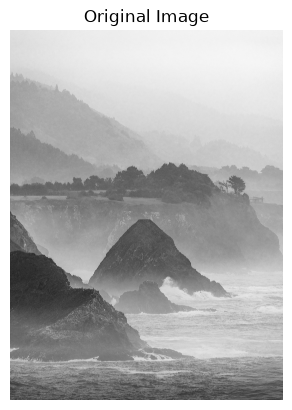

In [3]:
img = cv2.imread('Mn.jpg')

if img is None:
    print("Error: Could not find 'Mn.jpg'")
else:
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 4. Display the image inline using Matplotlib
    plt.imshow(img_rgb)
    plt.title('Original Image')
    plt.axis('off') # Hides the axis numbers
    plt.show()

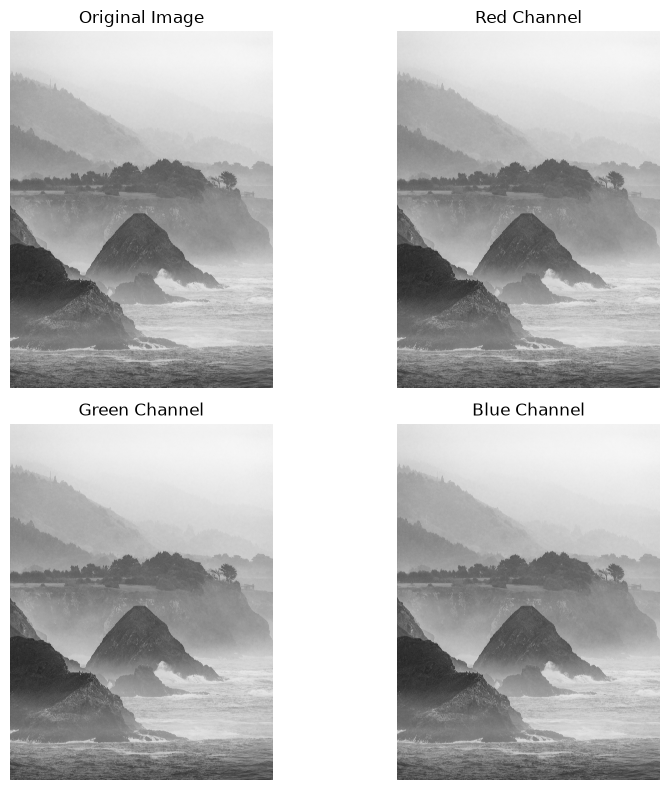

In [6]:
img = cv2.imread('Mn.jpg')
img=cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
R=img[:,:,0]
G=img[:,:,1]
B=img[:,:,2]
plt.figure(figsize=(9,8))

plt.subplot(2,2,1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(R,cmap='gray')
plt.title('Red Channel')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(G,cmap='gray')
plt.title('Green Channel')
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(B,cmap='gray')
plt.title('Blue Channel')
plt.axis('off')

plt.tight_layout()
plt.show()

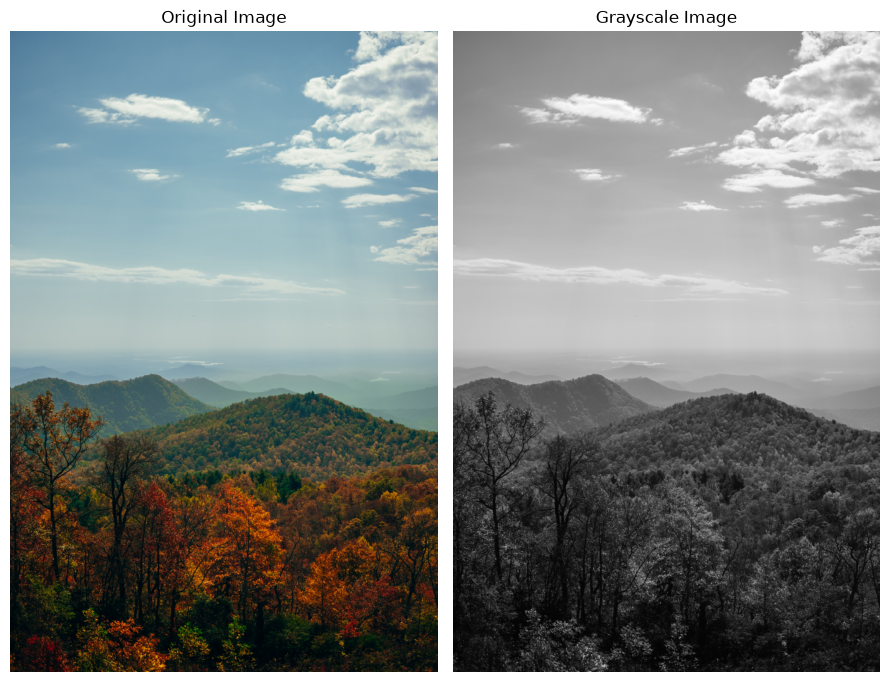

In [7]:
img = cv2.imread('Nm.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(9,8))

plt.subplot(1,2,1)
plt.imshow(img_rgb)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.tight_layout()
plt.show()


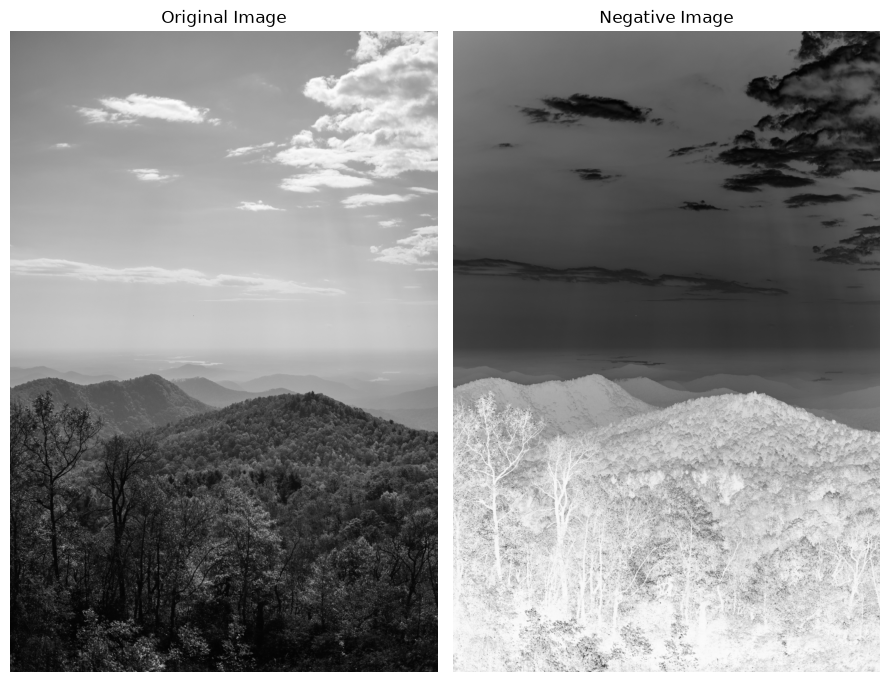

In [ ]:
img = cv2.imread('Nm.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

Negative=255-gray

plt.figure(figsize=(9,8))

plt.subplot(1,2,1)
plt.imshow(gray,cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(Negative, cmap='gray')
plt.title('Negative Image')
plt.axis('off')

plt.tight_layout()
plt.show()

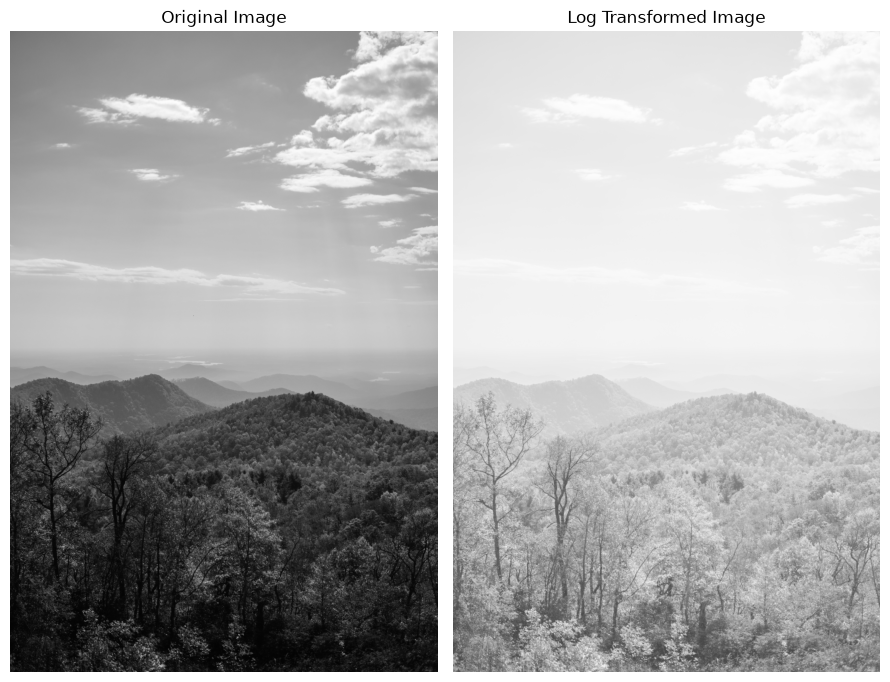

In [6]:
img = cv2.imread('Nm.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

gray_float=np.float32(gray)

c=255/np.log(1+255)

log_image= c* np.log(1+gray)

log_image=np.uint8(log_image)

plt.figure(figsize=(9,8))

plt.subplot(1,2,1)
plt.imshow(gray,cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(log_image, cmap='gray')
plt.title('Log Transformed Image')
plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:

# Load image in grayscale
img = cv2.imread('Mn.jpg', 0)

# Get image dimensions
M, N = img.shape

# Apply FFT
F = np.fft.fft2(img)

# Shift zero frequency to center
Fshift = np.fft.fftshift(F)

# Calculate distance from center
u = np.arange(M)
v = np.arange(N)
U, V = np.meshgrid(v, u)

D = np.sqrt((U - M/2)**2 + (V - N/2)**2)

# Set cutoff frequency
D0 = 30

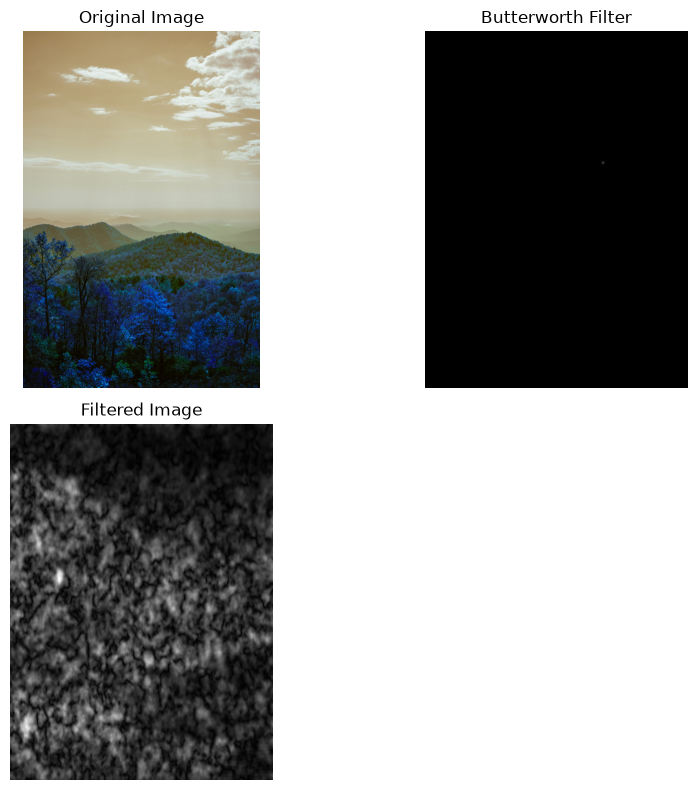

In [11]:
n=2
H=1/(1+D/D0)**(2*n)
G_Shift=Fshift*H
G=np.fft.ifftshift(G_Shift)
filtered=np.fft.ifft2(G)
filtered=np.abs(filtered)

plt.figure(figsize=(9,8))

plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(H, cmap='gray')
plt.title('Butterworth Filter')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

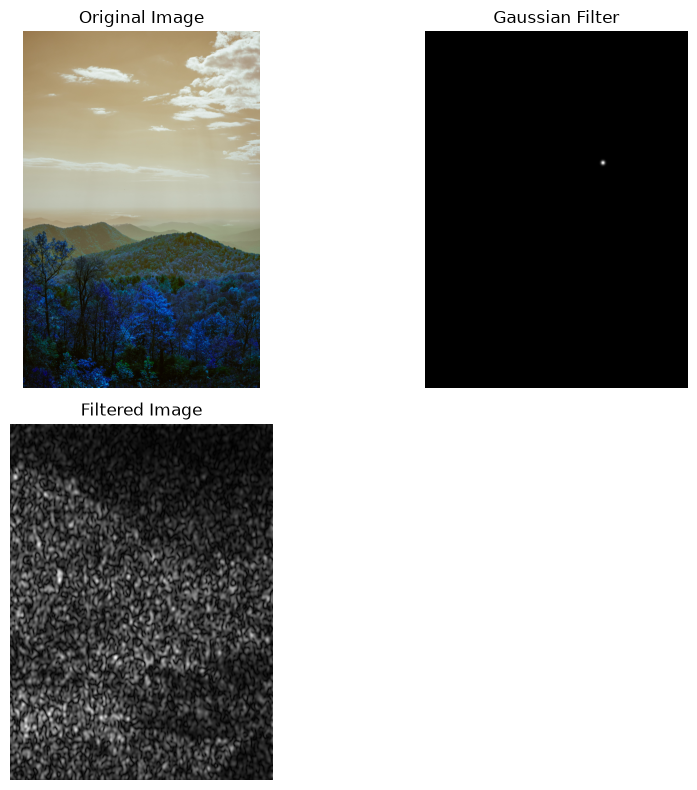

In [12]:

H=np.exp(-(D)**2/(2*D0**2))
G_Shift=Fshift*H
G=np.fft.ifftshift(G_Shift)
filtered=np.fft.ifft2(G)
filtered=np.abs(filtered)

plt.figure(figsize=(9,8))

plt.subplot(2,2,1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(H, cmap='gray')
plt.title('Gaussian Filter')
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()